In [1]:
# /// script
# requires-python = ">=3.14"
# dependencies = [
#     "folium",
#     "matplotlib",
#     "httpx2",
# ]
# ///

# async-titiler demo: GeoZarr

This notebook shows how to use a locally running **async-titiler** server to:

1. read metadata from GeoZarr stores (variables, dimensions, CRS, multiscales),
2. compute statistics to choose good visualization parameters,
3. display map tiles on an interactive map.

It covers two kinds of datasets:

- **Sentinel-2** reflectance: 2D `(y, x)` variables, one per spectral band.
- **Sentinel-1** backscatter: 3D `(time, y, x)` variables, organized in groups (orbit direction).

The `/geozarr` endpoints take the store location as a `url` query parameter and the array(s) to read as `variables`.

The first cell is an inline script metadata block ([PEP 723](https://peps.python.org/pep-0723/)) listing the notebook's dependencies, so tools like `uv` can install them automatically.

In [2]:
import json
import httpx2 as httpx
from folium import Map

from matplotlib import pyplot as plt

## Start the tiler server

The notebook talks to an async-titiler instance over HTTP. Before running the next cells, start the development server from the root of the `async-titiler` repository (command below). `--reload` restarts the server when the code changes, which is handy while developing.

In [3]:
# Run the local development server on your terminal

# uv run --extra server uvicorn async_titiler.main:app --port 8000 --workers 2 --reload

In [4]:
# Base URL of the tiler server started above (change it if you use another host/port)
titiler_endpoint = "http://127.0.0.1:8000"

## Sentinel-2 (2D arrays)

In [5]:
geozarr_url = "https://titiler-benchmark-public.s3.us-east-1.amazonaws.com/geozarrs/S2C_MSIL2A_20260810T125031_N0512_R095_T26SMJ_20260810T155917.zarr/measurements/reflectance/"

In [6]:
# Fetch file metadata (bounds, CRS, dtype, bands, overviews...)
r = httpx.get(
    f"{titiler_endpoint}/geozarr/info",
    params={
        "url": geozarr_url,
    },
).json()

# Pretty-print the JSON response
print(json.dumps(r, indent=4))
print("List of Available Variables:", [v["long_name"] for v in r.get("variables", [])])

{
    "bounds": [
        399965.0,
        4290245.0,
        509755.0,
        4400035.0
    ],
    "crs": "http://www.opengis.net/def/crs/EPSG/0/32626",
    "driver": "GeoZarr",
    "variables": [
        {
            "name": "b02",
            "group": null,
            "long_name": "b02",
            "dimensions": [
                "y",
                "x"
            ],
            "selectable_dimensions": {},
            "dtype": "float32",
            "valid_min": null,
            "valid_max": null,
            "multiscale": true
        },
        {
            "name": "b03",
            "group": null,
            "long_name": "b03",
            "dimensions": [
                "y",
                "x"
            ],
            "selectable_dimensions": {},
            "dtype": "float32",
            "valid_min": null,
            "valid_max": null,
            "multiscale": true
        },
        {
            "name": "b04",
            "group": null,
            "long_name

#### What the `/info` response tells us

- **CRS**: `EPSG:32626` (WGS 84 / UTM zone 26N). `bounds` are given in this projected CRS (meters), not in longitude/latitude.
- **Extent**: `[399965, 4290245, 509755, 4400035]`, a square of about 110 km × 110 km. This is the footprint of one Sentinel-2 tile (26SMJ).
- **Variables**: 12 spectral bands (`b01` to `b12`, plus `b8a`). Each is a 2D `(y, x)` array with **no extra dimension to select** (`selectable_dimensions` is empty). We only have to pick which variable(s) to read.
- **Data type**: `float32` surface reflectance. `valid_min`/`valid_max` are not set, so we have to compute statistics to learn the value range (next step).
- **Multiscales**: every variable has `multiscale: true`. The `attributes.multiscales.layout` lists the available resolution levels:

  | level | resolution | shape (y, x) |
  |-------|-----------:|-------------:|
  | `r10m`  | 10 m  | 10980 × 10980 |
  | `r20m`  | 20 m  | 5490 × 5490 |
  | `r60m`  | 60 m  | 1830 × 1830 |
  | `r120m` | 120 m | 915 × 915 |
  | `r360m` | 360 m | 305 × 305 |
  | `r720m` | 720 m | 152 × 152 |

  Like COG overviews, these levels let the tiler read a coarser level for low zoom tiles or statistics, so it does not have to load the full 10 m array.

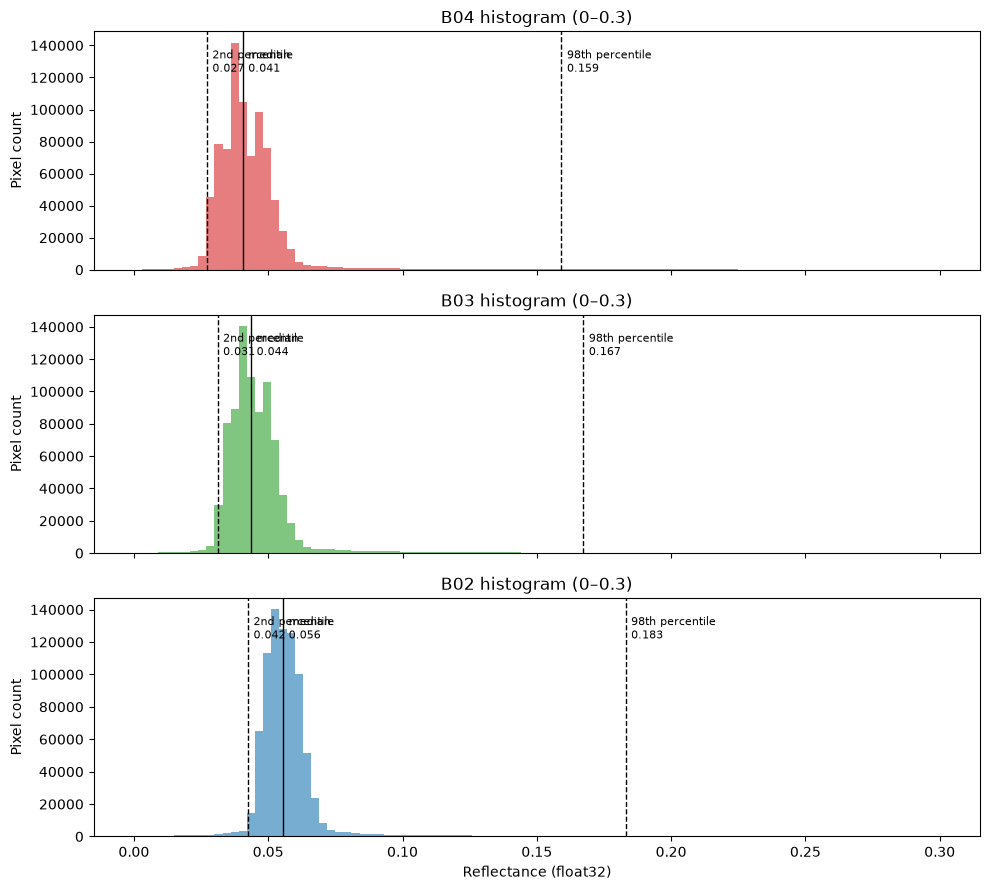

In [7]:
# Variables are of type float32, we will need to rescale the tiles to get data in uint8 range.
# Getting the statistics first will help determine the appropriate rescale values.

# Display the histogram of each variable to choose rescale values.
# As for the GeoTIFF, the default 10-bin histogram is too coarse (~98% of pixels in the first bin),
# so we request a finer histogram focused on where the reflectance values actually are.
r = httpx.get(
    f"{titiler_endpoint}/geozarr/statistics",
    params=(
        ("url", geozarr_url),
        ("variables", "b04"),
        ("variables", "b03"),
        ("variables", "b02"),
        ("histogram_bins", 100),
        # NOTE: Surface reflectance mostly falls between 0 and 0.3 (dataset knowledge)
        ("histogram_range", "0,0.3"),
    ),
).json()

# One color per band: B04 = red, B03 = green, B02 = blue
colors = {"b04": "tab:red", "b03": "tab:green", "b02": "tab:blue"}

fig, axes = plt.subplots(3, 1, figsize=(10, 9), sharex=True)

# Response keys are `variables1`, `variables2`, ... (in request order); the variable name is in `description`
for ax, stats in zip(axes, r.values()):
    name = stats["description"]
    counts, edges = stats["histogram"]  # len(edges) == len(counts) + 1
    ax.stairs(counts, edges, fill=True, alpha=0.6, color=colors.get(name))

    # Mark the values commonly used as rescale bounds
    for value, label, style in [
        (stats["percentile_2"], "2nd percentile", "--"),
        (stats["median"], "median", "-"),
        (stats["percentile_98"], "98th percentile", "--"),
    ]:
        ax.axvline(value, color="k", linestyle=style, linewidth=1)
        ax.annotate(
            f"{label}\n{value:.3f}",
            (value, max(counts)),
            xytext=(4, -4),
            textcoords="offset points",
            va="top",
            fontsize=8,
        )

    ax.set_title(f"{name.upper()} histogram (0–0.3)")
    ax.set_ylabel("Pixel count")

axes[-1].set_xlabel("Reflectance (float32)")
fig.tight_layout()
plt.show()

#### Display a true color image

Most reflectance values fall between the 2nd and 98th percentiles shown above, so we use `rescale=0.03,0.2` to stretch the `float32` values to the `0-255` range of a PNG/JPEG tile.

- Listing `variables` 3 times (`b04`, `b03`, `b02`) makes a 3 band (red, green, blue) image, in that order.
- We don't call the tile endpoint ourselves. We ask for a **TileJSON** document that gives the dataset bounds (in longitude/latitude) and a tile URL template (`.../{z}/{x}/{y}?...`) with our query parameters already in it. Folium uses that template to load tiles.

In [8]:
# Display tiles (first fetch tilejson to get the layer bounds and tiles URL)
r = httpx.get(
    f"{titiler_endpoint}/geozarr/WebMercatorQuad/tilejson.json",
    params=(
        ("url", geozarr_url),
        ("variables", "b04"),
        ("variables", "b03"),
        ("variables", "b02"),
        ("rescale", "0.03,0.2"),
        ("tilesize", 256),
    ),
).json()

# Bounds are in geographic coordinates: [west, south, east, north]
bounds = r["bounds"]

# Center the map on the dataset (folium expects (lat, lon))
m = Map(
    location=((bounds[1] + bounds[3]) / 2, (bounds[0] + bounds[2]) / 2),
    zoom_start=10,
    tiles=r["tiles"][0],
    attr="Sentinel-2",
)
m

## Sentinel-1 (3D arrays, Time/Y/X)

In [ ]:
geozarr_url = "https://titiler-benchmark-public.s3.us-east-1.amazonaws.com/geozarrs/s1-rtc-32UPB.zarr"

In [9]:
# Fetch metadata for the root store
r = httpx.get(
    f"{titiler_endpoint}/geozarr/info",
    params={
        "url": geozarr_url,
    },
).json()

# Pretty-print the JSON response
print(json.dumps(r, indent=4))
print("List of Available Variables:", [v["long_name"] for v in r.get("variables", [])])

{
    "bounds": [
        399965.0,
        4290245.0,
        509755.0,
        4400035.0
    ],
    "crs": "http://www.opengis.net/def/crs/EPSG/0/32626",
    "driver": "GeoZarr",
    "variables": [
        {
            "name": "b02",
            "group": null,
            "long_name": "b02",
            "dimensions": [
                "y",
                "x"
            ],
            "selectable_dimensions": {},
            "dtype": "float32",
            "valid_min": null,
            "valid_max": null,
            "multiscale": true
        },
        {
            "name": "b03",
            "group": null,
            "long_name": "b03",
            "dimensions": [
                "y",
                "x"
            ],
            "selectable_dimensions": {},
            "dtype": "float32",
            "valid_min": null,
            "valid_max": null,
            "multiscale": true
        },
        {
            "name": "b04",
            "group": null,
            "long_name

### What the root `/info` response tells us

- **Groups**: the store has two groups, `ascending` and `descending` (the satellite orbit direction). Each group has the same 3 variables: `border_mask`, `vh` and `vv`. At the root level, variable names are prefixed with their group (`ascending:vv`, `descending:vh`, ...).
- **Dimensions**: every variable is a **3D** `(time, y, x)` array. `time` is a *selectable dimension* with 3 steps (`start: 0`, `end: 2`, `step: 1`).
- **No georeferencing at the root**: `bounds` is the whole world (`[-180, -90, 180, 90]`) in `EPSG:4326`, and `attributes` is empty. The CRS and multiscales metadata are stored on each group, not on the root, so the tiler falls back to default values here.

To get the real CRS, extent and resolution levels, let's point the `url` at one group: the `ascending` orbit.

In [10]:
geozarr_url = "https://titiler-benchmark-public.s3.us-east-1.amazonaws.com/geozarrs/s1-rtc-32UPB.zarr/ascending"

r = httpx.get(
    f"{titiler_endpoint}/geozarr/info",
    params={
        "url": geozarr_url,
    },
).json()

# Pretty-print the JSON response
print(json.dumps(r, indent=4))
print("List of Available Variables:", [v["long_name"] for v in r.get("variables", [])])

{
    "bounds": [
        600000.0000002288,
        5590200.000002797,
        709800.0000002288,
        5700000.000002797
    ],
    "crs": "http://www.opengis.net/def/crs/EPSG/0/32632",
    "driver": "GeoZarr",
    "variables": [
        {
            "name": "border_mask",
            "group": null,
            "long_name": "border_mask",
            "dimensions": [
                "time",
                "y",
                "x"
            ],
            "selectable_dimensions": {
                "time": {
                    "type": "interval",
                    "start": 0,
                    "end": 2,
                    "step": 1
                }
            },
            "dtype": "uint8",
            "valid_min": null,
            "valid_max": null,
            "multiscale": true
        },
        {
            "name": "vh",
            "group": null,
            "long_name": "vh",
            "dimensions": [
                "time",
                "y",
               

### What the `/info` response tells us

- **CRS**: `EPSG:32632` (WGS 84 / UTM zone 32N). `bounds` are given in this projected CRS (meters), not in longitude/latitude.
- **Extent**: `[600000, 5590200, 709800, 5700000]`, a square of about 110 km × 110 km. This is the Sentinel-2 grid tile 32UPB, which the Sentinel-1 data was resampled onto.
- **Variables**:
  - `vv` and `vh` (`float32`): radar backscatter for the two polarizations (VV = vertical send/vertical receive, VH = vertical send/horizontal receive).
  - `border_mask` (`uint8`): a mask that flags invalid pixels at the edge of the acquisition.
- **Dimensions**: each variable is `(time, y, x)`, with 3 time steps (`selectable_dimensions.time`). If we don't select a time step, the tiler reads **all of them and returns each step as a band** (`time1`, `time2`, `time3`). To read a single date, add a `sel` query parameter (e.g. `sel=time=0`).
- **Data range**: `valid_min`/`valid_max` are not set, so we have to compute statistics to learn the value range (next step).
- **Multiscales**: every variable has `multiscale: true`. The `attributes.multiscales.layout` lists the available resolution levels (built with `average` resampling):

  | level   | resolution | shape (y, x)  |
  |---------|-----------:|--------------:|
  | `r10m`  | 10 m       | 10980 × 10980 |
  | `r20m`  | 20 m       | 5490 × 5490   |
  | `r60m`  | 60 m       | 1830 × 1830   |
  | `r120m` | 120 m      | 915 × 915     |
  | `r360m` | 360 m      | 305 × 305     |
  | `r720m` | 720 m      | 153 × 153     |

  Like COG overviews, these levels let the tiler read a coarser level for low zoom tiles or statistics, so it does not have to load the full 10 m array.

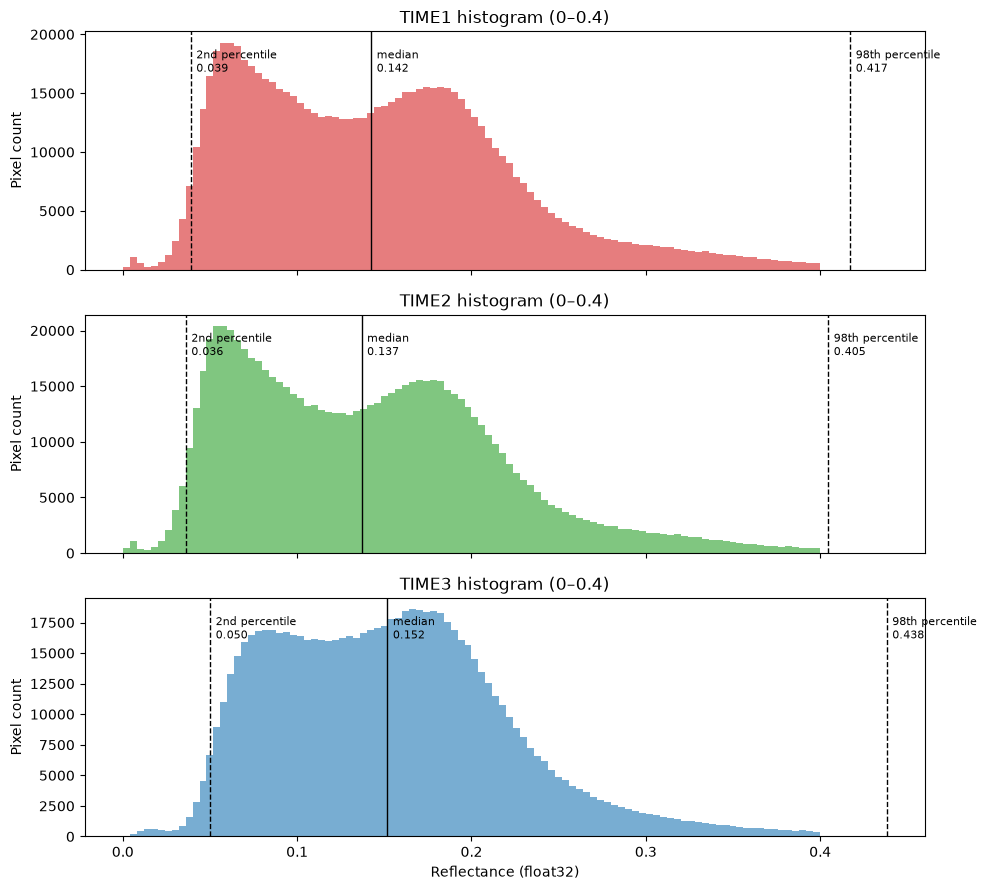

In [13]:
# Display the histogram to choose rescale values.
# The default histogram (10 bins over the full min/max range) is too coarse: almost every pixel
# lands in the first bin because of a few very bright outliers. We request a finer histogram
# focused on the range where the data actually is, using `histogram_bins` and `histogram_range`.
r = httpx.get(
    f"{titiler_endpoint}/geozarr/statistics",
    params={
        "url": geozarr_url,
        "variables": "vv",
        "histogram_bins": 100,
        "histogram_range": "0,0.4",  # Dataset knowledge
    },
).json()

# One color per band: time1 = red, time2 = green, time3 = blue
colors = {"time1": "tab:red", "time2": "tab:green", "time3": "tab:blue"}

fig, axes = plt.subplots(3, 1, figsize=(10, 9), sharex=True)

# Response keys are `time1`, `time2`, `time3`, ... (in request order); the name is in `description`
for ax, stats in zip(axes, r.values()):
    name = stats["description"]
    counts, edges = stats["histogram"]  # len(edges) == len(counts) + 1
    ax.stairs(counts, edges, fill=True, alpha=0.6, color=colors.get(name))

    # Mark the values commonly used as rescale bounds
    for value, label, style in [
        (stats["percentile_2"], "2nd percentile", "--"),
        (stats["median"], "median", "-"),
        (stats["percentile_98"], "98th percentile", "--"),
    ]:
        ax.axvline(value, color="k", linestyle=style, linewidth=1)
        ax.annotate(
            f"{label}\n{value:.3f}",
            (value, max(counts)),
            xytext=(4, -4),
            textcoords="offset points",
            va="top",
            fontsize=8,
        )

    ax.set_title(f"{name.upper()} histogram (0–0.4)")
    ax.set_ylabel("Pixel count")

axes[-1].set_xlabel("Reflectance (float32)")
fig.tight_layout()
plt.show()

#### Display a single date

Because `vv` is a 3D array, a request without a selection returns one band per time step. To show one date, we use `sel=time=0` to pick the first time step (by **index**, because the store has no time coordinate values).

From the histograms above, `rescale=0.05,0.4` covers most of the `vv` values.

`min_lon`/`min_lat`/`max_lon`/`max_lat` with `max_bounds=True` keep the map view inside the dataset extent.

In [14]:
# Display tiles (first fetch tilejson to get the layer bounds and tiles URL)
# NOTE: we want to display the first time slice of the "vv" variable with the specified rescale range
# we use the `sel` query-parameter with `time=0` to select the first time slice
# if coordinates conventions where present we could have done `time=2025-01-01...`

r = httpx.get(
    f"{titiler_endpoint}/geozarr/WebMercatorQuad/tilejson.json",
    params=(
        ("url", geozarr_url),
        ("variables", "vv"),
        ("sel", "time=0"),
        ("rescale", "0.05,0.4"),
        ("tilesize", 256),
    ),
).json()

# Bounds are in geographic coordinates: [west, south, east, north]
bounds = r["bounds"]

# Center the map on the dataset (folium expects (lat, lon))
m = Map(
    location=((bounds[1] + bounds[3]) / 2, (bounds[0] + bounds[2]) / 2),
    zoom_start=10,
    min_lon=bounds[0],
    min_lat=bounds[1],
    max_lon=bounds[2],
    max_lat=bounds[3],
    max_bounds=True,
    tiles=r["tiles"][0],
    attr="Sentinel-1",
)
m

#### Time composite

Without `sel`, the tiler returns the 3 time steps of `vv` as 3 bands (`time1`, `time2`, `time3`), which display as red, green and blue.

How to read the colors:
- **Gray** pixels: the backscatter is about the same on all 3 dates (no change).
- **Colored** pixels: the backscatter changed between dates. For example, a red pixel was brighter on the first date (crops, flooding, construction, ...).

In [22]:
# Time composite (r: time1, g: time2, b: time3)

r = httpx.get(
    f"{titiler_endpoint}/geozarr/WebMercatorQuad/tilejson.json",
    params=(
        ("url", geozarr_url),
        ("variables", "vv"),
        ("rescale", "0.05,0.4"),
        ("tilesize", 256),
    ),
).json()

# Bounds are in geographic coordinates: [west, south, east, north]
bounds = r["bounds"]

# Center the map on the dataset (folium expects (lat, lon))
m = Map(
    location=((bounds[1] + bounds[3]) / 2, (bounds[0] + bounds[2]) / 2),
    zoom_start=10,
    min_lon=bounds[0],
    min_lat=bounds[1],
    max_lon=bounds[2],
    max_lat=bounds[3],
    max_bounds=True,
    tiles=r["tiles"][0],
    attr="Sentinel-1",
)
m

#### Polarization composite (one date)

A common way to show dual-polarization SAR data is `R: VV, G: VH, B: VV/VH`.

- `sel=time=0` applies to **both** variables, so each one becomes a single 2D band.
- The bands are then named `variables1` (`vv`) and `variables2` (`vh`), in request order, and the `expression` uses those names. `;` separates the output bands.
- `rescale` is given once per output band, in the same order as the expression.

In [30]:
# Variables composite (vv and vh)
# This composite uses both "vv" and "vh" variables
# - we select the first time slice of both variables (to get two 1D arrays)
# - we then apply a custom expression to create a RGB composite (vv,vh,vv/vh)
r = httpx.get(
    f"{titiler_endpoint}/geozarr/WebMercatorQuad/tilejson.json",
    params=(
        ("url", geozarr_url),
        ("variables", "vv"),
        ("variables", "vh"),
        ("sel", "time=0"),
        ("rescale", "0,0.3"),
        ("rescale", "0,0.05"),
        ("rescale", "0,25"),
        ("expression", "variables1;variables2;variables1/variables2"),
        ("tilesize", 256),
    ),
).json()

# Bounds are in geographic coordinates: [west, south, east, north]
bounds = r["bounds"]

# Center the map on the dataset (folium expects (lat, lon))
m = Map(
    location=((bounds[1] + bounds[3]) / 2, (bounds[0] + bounds[2]) / 2),
    zoom_start=10,
    min_lon=bounds[0],
    min_lat=bounds[1],
    max_lon=bounds[2],
    max_lat=bounds[3],
    max_bounds=True,
    tiles=r["tiles"][0],
    attr="Sentinel-1",
)
m

#### Polarization composite (mean over time)

Instead of picking one date, we can **reduce** the time dimension. `reduce=time::mean` averages the 3 time steps of each variable, so each one becomes a single 2D band (`<dimension>::<method>`).

Averaging dates also reduces speckle, the grainy noise found in SAR images, so this composite looks smoother than the single date one. The expression and rescale values are the same as in the previous cell.

In [26]:
# Variables composite (vv and vh)
# This composite uses both "vv" and "vh" variables
# - we compute the mean over the time dimension for both variables
# - we then apply a custom expression to create a RGB composite (vv,vh,vv/vh)
r = httpx.get(
    f"{titiler_endpoint}/geozarr/WebMercatorQuad/tilejson.json",
    params=(
        ("url", geozarr_url),
        ("variables", "vv"),
        ("variables", "vh"),
        ("reduce", "time::mean"),
        ("rescale", "0.05,0.4"),
        ("rescale", "0.05,0.4"),
        ("rescale", "0,1"),
        ("expression", "variables1;variables2;variables1/variables2"),
        ("tilesize", 256),
    ),
).json()

# Bounds are in geographic coordinates: [west, south, east, north]
bounds = r["bounds"]

# Center the map on the dataset (folium expects (lat, lon))
m = Map(
    location=((bounds[1] + bounds[3]) / 2, (bounds[0] + bounds[2]) / 2),
    zoom_start=10,
    min_lon=bounds[0],
    min_lat=bounds[1],
    max_lon=bounds[2],
    max_lat=bounds[3],
    max_bounds=True,
    tiles=r["tiles"][0],
    attr="Sentinel-1",
)
m